# BIOT 6900 · Module 9 — Notebook 3
## Clinical NLP: community-acquired pneumonia and outcome leakage

**Synthetic coursework only.** All 400 patients and 1,200 notes are generated locally.
The outcome is subsequent in-hospital death (`died`), not ICU admission: everyone in
the supplied generator is already admitted to the ICU.

**Seed status:** the executed example uses **20261111**, a temporary seed, because my
numeric student ID has not been entered - since this notebook is uploaded to github. 

I kept the supplied engine unchanged and put the extraction checks and evaluation
improvements in separate cells. The deliberately leaky models are diagnostic
comparisons; the final model uses only the permitted early information.

## The engine (provided, unchanged)

This is the original teaching engine. Its synthetic distributions and treatment
templates are retained so that the leakage experiment stays comparable to the
assignment. The safer extraction wrapper and evaluation helpers below are used
instead of the original single-split importance helper.

In [1]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# --- ConText assertion engine (from Notebook 2) ---
NEG_PRE  = ["no evidence of", "no acute", "denies", "denied", "without", "negative for", "ruled out for", "r/o", "no "]
NEG_POST = ["ruled out", "was negative", "is negative", "unlikely", "resolved"]
PSEUDO   = ["no change", "no increase", "no further", "not only", "cannot be ruled out", "gram negative"]
FAM      = ["mother", "father", "sister", "brother", "parent", "family history", "fh "]
HIST     = ["history of", "h/o", "hx of", "prior", "previous", "status post", "s/p", "chronic"]
HYPO     = ["if ", "would ", "should ", "to prevent", "risk of", "monitor for"]
def _sents(t): return [s.strip() for s in re.split(r"[.;\n]", t) if s.strip()]
def assertion(term, text):
    for sent in _sents(text):
        low = sent.lower()
        m = re.search(r"\b" + re.escape(term.lower()) + r"\b", low)
        if not m: continue
        pos = m.start(); pseudo = any(p in low for p in PSEUDO)
        pre = low[max(0, pos-60):pos]; post = low[pos+len(term):pos+len(term)+45]
        if any(x in low for x in FAM): return "family"
        if any(x in pre for x in HYPO): return "hypothetical"
        if not pseudo and (any(x in pre for x in NEG_PRE) or any(x in post for x in NEG_POST)): return "absent"
        if any(x in pre for x in HIST): return "historical"
        return "present"
    return None

def concept_present(synonyms, note_texts):
    for v in synonyms:
        for t in note_texts:
            if assertion(v, t) == "present":
                return 1
    return 0

# two features injected that you did NOT configure (diagnose them in Part D):
WILDCARDS = {
    "lactate_not_clearing": ["failing to clear", "not clearing"],
    "renal_replacement":    ["dialysis", "renal replacement therapy"],
}

def build_world(cfg, seed=2024, N=400):
    rng = np.random.default_rng(seed)
    age = rng.integers(40, 92, N); sex = rng.choice(["M", "F"], N)
    lactate = rng.normal(2.2, 1.3, N).clip(0.5, 14); creatinine = rng.normal(1.1, 0.6, N).clip(0.3, 9)
    sig_names = list(cfg["signals"]); con_names = list(cfg["consequences"])
    sig_present = {s: rng.random(N) < rng.uniform(0.18, 0.30) for s in sig_names}
    w_sig = rng.random(N) < 0.22                               # wildcard SIGNAL (a cause)
    logit = -2.3 + 0.045*(age-65) + 0.55*(lactate-2) + 0.3*(creatinine-1) + 0.55*w_sig
    for s in sig_names: logit = logit + 0.6*sig_present[s]
    died = (rng.random(N) < 1/(1+np.exp(-logit))).astype(int)
    w_leak = ((died == 1) & (rng.random(N) < 0.5)) | ((died == 0) & (rng.random(N) < 0.10))  # wildcard LEAK

    def notes_for(i):
        adm = [f"{age[i]}{sex[i]} admitted to the ICU.", f"Lactate {lactate[i]:.1f}, creatinine {creatinine[i]:.1f}."]
        for s in sig_names:
            syns = cfg["signals"][s]
            if sig_present[s][i]: adm.append(f"Clinical note: {rng.choice(syns)} present.")
            elif rng.random() < 0.25: adm.append(f"No evidence of {syns[0]}.")
        if w_sig[i]: adm.append("Lactate failing to clear despite resuscitation.")
        if rng.random() < 0.2: adm.append("History of MI, no acute chest pain.")
        prog = ["Progress note, hospital day 2."]
        if rng.random() < 0.15: prog.append("Family history of diabetes.")
        disch = ["Discharge / final note."]
        if died[i]:
            for c in con_names:
                if rng.random() < 0.5: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Required renal replacement therapy (dialysis).")
        else:
            for c in con_names:
                if rng.random() < 0.10: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Brief dialysis for contrast, since stopped.")
            disch.append(rng.choice(["Tolerating diet, ambulating.", "Stable for discharge."]))
        return [" ".join(adm), " ".join(prog), " ".join(disch)]

    NOTES = [notes_for(i) for i in range(N)]
    struct = pd.DataFrame({"subject_id": np.arange(1, N+1), "age": age, "sex": sex,
                           "lactate": lactate.round(1), "creatinine": creatinine.round(1), "died": died})
    struct.loc[rng.random(N) < 0.15, "lactate"] = np.nan
    return struct, NOTES

def cv_auroc(df, cols):
    X, y = df[cols].values, df["died"].values
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
    s = cross_val_score(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
    return s.mean(), s.std()

def perm_importance(df, cols):
    X, y = df[cols].values, df["died"].values
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    pi = permutation_importance(pipe, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=0)
    return pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)

print("engine loaded.")

engine loaded.


## Part A — Configure the disease

I chose **community-acquired pneumonia in adults requiring ICU care**. My early
features describe impaired oxygenation, the extent of lung involvement, and acute
neurological dysfunction. These are plausible baseline severity findings, while
ventilation, vasopressor support, and a transition to comfort-focused care are
later responses to the clinical course in this generator.

| Configured concept | Why I placed it here |
|---|---|
| `hypoxemia` | Impaired oxygenation can be present at assessment and contribute to organ dysfunction. |
| `multilobar_infiltrates` | Involvement of several lung lobes reflects a larger burden of pneumonia before later escalation. |
| `acute_confusion` | New confusion can be an early sign of systemic illness; it is a severity marker rather than a demonstrated cause of death. |
| `invasive_ventilation` | Respiratory support documented after deterioration, in the final note. |
| `vasopressor_support` | A response to circulatory failure, documented in the final note. |
| `comfort_care` | A later care decision influenced by prognosis and preferences, not a baseline disease finding. |

Reduced oxygenation, multilobar infiltrates, and confusion are included among the
ATS/IDSA pneumonia severity criteria. I am not equating a general hypoxemia
mention with the guideline's quantitative oxygenation threshold. A useful
predictor also does not have to be causal.

**Prediction time:** the first ICU assessment *after initial resuscitation and
any early repeat lactate measurement*, before day-2 and final notes. I assume the
admission note and baseline structured values are available then. This makes the
lactate-trend wildcard a possible early feature; it would not be available at
first arrival. The generator has no real timestamps, so this is an explicit
teaching assumption, not a verified clinical prediction window.

In [2]:
CONFIG = {
    "disease": "Community-acquired pneumonia requiring ICU care",
    "signals": {
        "hypoxemia": ["hypoxemia", "hypoxaemia", "low blood oxygen"],
        "multilobar_infiltrates": [
            "multilobar infiltrates", "multilobar opacities", "infiltrates in multiple lobes"
        ],
        "acute_confusion": ["acute confusion", "new disorientation", "new onset confusion"],
    },
    "consequences": {
        "invasive_ventilation": [
            "intubated", "invasive mechanical ventilation", "endotracheal intubation"
        ],
        "vasopressor_support": ["vasopressors", "norepinephrine infusion", "pressor support"],
        "comfort_care": ["comfort measures only", "comfort-focused care", "cmo"],
    },
}


SEED = 20261111
N_PATIENTS = 400

assert 2 <= len(CONFIG["signals"]) <= 3
assert 2 <= len(CONFIG["consequences"]) <= 3
assert not (set(CONFIG["signals"]) & set(CONFIG["consequences"]))
assert not ((set(CONFIG["signals"]) | set(CONFIG["consequences"])) & set(WILDCARDS))
assert all(len(v) >= 2 for group in (CONFIG["signals"], CONFIG["consequences"])
           for v in group.values())

struct, NOTES = build_world(CONFIG, seed=SEED, N=N_PATIENTS)
assert len(struct) == len(NOTES) == N_PATIENTS
assert struct.subject_id.is_unique
assert all(len(notes) == 3 for notes in NOTES)
print(f"SYNTHETIC: {CONFIG['disease']}")
print(f"SEED = {SEED}")
print(f"{len(struct)} patients, {sum(map(len, NOTES))} notes")
print(f"Deaths = {struct.died.sum()}/{len(struct)} ({struct.died.mean():.1%}), preserving real-world class imbalance scenario")
print("Example patient notes:")
for label, note in zip(["admission", "day 2", "final"], NOTES[0]):
    print(f"  [{label}] {note}")

SYNTHETIC: Community-acquired pneumonia requiring ICU care
SEED = 20261111
400 patients, 1200 notes
Deaths = 92/400 (23.0%), preserving real-world class imbalance scenario
Example patient notes:
  [admission] 91M admitted to the ICU. Lactate 3.2, creatinine 0.3. Clinical note: multilobar opacities present.
  [day 2] Progress note, hospital day 2.
  [final] Discharge / final note. Endotracheal intubation. Norepinephrine infusion. Comfort-focused care.


## Part B — Extract features

The vocabulary maps several phrases to one binary concept. I create both the
all-notes features needed for the leakage demonstration and an admission-only
version for the final model. `0` means **no affirmed current mention was found**,
not that the patient definitely lacks the condition.

The supplied extractor stops at the first mention of a synonym in a note. This
can miss an affirmed mention after an earlier negative or historical mention.
My small wrapper checks each sentence/contrast clause. The original engine remains
unchanged. This is still a limited rule-based exercise (in my experience healthcare 
professionals have variety ways to say certain things - varies from region to region, 
from hospital to hospital) - need vast amount of regular expression patterns to capture at least 90% of them.

In [3]:
import re
import pandas as pd

# Requires CONFIG, WILDCARDS, struct, NOTES, and the supplied assertion().
# NOTES must be in the same patient order as struct.
ALL_CONCEPTS = {
    **CONFIG["signals"],
    **CONFIG["consequences"],
    **WILDCARDS,
}
concept_cols = list(ALL_CONCEPTS)


# Notebook 2's rules, kept separate from the supplied engine.
COURSE_NEG_PRE = [
    "no evidence of", "no acute", "denies", "denied", "without",
    "negative for", "ruled out for", "r/o", "no "
]

COURSE_NEG_POST = [
    "ruled out", "was negative", "is negative", "unlikely",
    "resolved", "not present"
]

COURSE_PSEUDO = [
    "no change", "no increase", "no further", "not only",
    "cannot be ruled out", "gram negative", "no interval"
]

COURSE_FAM = [
    "mother", "father", "sister", "brother", "parent",
    "family history", "fh "
]

COURSE_HIST = [
    "history of", "h/o", "hx of", "prior", "previous",
    "status post", "s/p", "chronic", "years ago"
]

COURSE_HYPO = [
    "if ", "would ", "should ", "to prevent",
    "risk of", "in case", "monitor for"
]


def note_clauses(text):
    """Split sentences and simple contrast clauses; preserve decimals."""
    parts = re.split(
        r"(?<!\d)\.|\.(?!\d)|[;\n]|\b(?:but|however|whereas)\b",
        text,
        flags=re.I,
    )
    return [part.strip() for part in parts if part.strip()]


def assertion_course(term, clause):
    """Apply Notebook 2's assertion rules to one separated clause."""
    low = clause.lower()
    match = re.search(
        r"\b" + re.escape(term.lower()) + r"\b",
        low,
    )

    if match is None:
        return None

    pre = low[max(0, match.start() - 60):match.start()]
    post = low[match.end():match.end() + 45]
    pseudo = any(cue in low for cue in COURSE_PSEUDO)

    # Preserve the course engine's rule precedence.
    if any(cue in low for cue in COURSE_FAM):
        return "family"

    if any(cue in pre for cue in COURSE_HYPO):
        return "hypothetical"

    if not pseudo and (
        any(cue in pre for cue in COURSE_NEG_PRE)
        or any(cue in post for cue in COURSE_NEG_POST)
    ):
        return "absent"

    if any(cue in pre for cue in COURSE_HIST):
        return "historical"

    return "present"


def concept_present_checked(synonyms, note_texts):
    """1 if any mention is PRESENT under the course rules."""
    for text in note_texts:
        for clause in note_clauses(text):
            for synonym in synonyms:
                if assertion_course(synonym, clause) == "present":
                    return 1
    return 0


def extract_concepts(note_sets):
    assert len(note_sets) == len(struct), (
        "Notes and patient rows must align."
    )
    assert struct.subject_id.notna().all(), (
        "Patient IDs cannot be missing."
    )
    assert struct.subject_id.is_unique, (
        "Expected one row per patient."
    )

    out = pd.DataFrame({
        "subject_id": struct.subject_id.to_numpy()
    })

    for name, synonyms in ALL_CONCEPTS.items():
        out[name] = [
            concept_present_checked(synonyms, notes)
            for notes in note_sets
        ]

    return out


# Regression checks for the configured hypoxemia concept.
# Course convention:
# "possible" and "cannot be ruled out" can count as PRESENT.
# Therefore PRESENT does not necessarily mean a confirmed diagnosis.
# There is deliberately no blanket uncertainty filter.
checks = [
    ("Hypoxemia present.", 1),
    ("Hypoxaemia present.", 1),
    ("No evidence of hypoxemia.", 0),
    ("Hypoxemia not present.", 0),
    ("Hypoxemia ruled out.", 0),
    ("History of hypoxemia.", 0),
    ("Mother had hypoxemia.", 0),
    ("Monitor for hypoxemia.", 0),
    ("In case hypoxemia develops, reassess.", 0),
    ("Possible hypoxemia.", 1),
    ("Hypoxemia cannot be ruled out.", 1),
    ("No change in hypoxemia.", 1),
    ("No interval change in hypoxemia.", 1),
    ("Hypoxemia present, possible pneumonia.", 1),
    (
        "No evidence of hypoxemia. "
        "Hypoxemia present on reassessment.",
        1,
    ),
    (
        "No hypoxemia initially but "
        "hypoxemia present on reassessment.",
        1,
    ),
]

for text, expected in checks:
    observed = concept_present_checked(
        CONFIG["signals"]["hypoxemia"],
        [text],
    )
    assert observed == expected, (
        f"{text}: expected {expected}, got {observed}"
    )

print(f"Assertion checks passed: {len(checks)}/{len(checks)}")


# All notes: used for the leakage demonstration.
feat = extract_concepts(NOTES)

# Admission only: used for the final early model.
# This generator places the admission note first.
early_feat = extract_concepts([notes[:1] for notes in NOTES])


# Validate feature values and patient alignment.
assert feat[concept_cols].isin([0, 1]).all().all()
assert early_feat[concept_cols].isin([0, 1]).all().all()
assert feat.subject_id.equals(early_feat.subject_id)

# An admission-positive concept must also be positive across all notes.
assert (
    early_feat[concept_cols] <= feat[concept_cols]
).all().all()


# Compare with the unchanged starter assertion engine.
# Use assertion() directly to avoid the different concept_present()
# argument conventions in Notebooks 2 and 3.
original_feat = pd.DataFrame({
    name: [
        int(any(
            assertion(synonym, text) == "present"
            for synonym in synonyms
            for text in notes
        ))
        for notes in NOTES
    ]
    for name, synonyms in ALL_CONCEPTS.items()
})

# Differences are diagnostic, not automatically errors:
# an improved extractor can legitimately disagree with the starter.
changed = feat[concept_cols].ne(original_feat[concept_cols])

print(
    "Patient-concept differences from starter:",
    int(changed.to_numpy().sum()),
)

if changed.any().any():
    print(changed.sum()[changed.any()].to_string())


# Patient-level counts.
counts = pd.DataFrame({
    "all_notes_present": feat[concept_cols].sum(),
    "admission_present": early_feat[concept_cols].sum(),
})

# Present in a later note, with no PRESENT mention at admission.
counts["final_or_later_only"] = (
    counts["all_notes_present"] - counts["admission_present"]
)

counts["percent_all_patients"] = (
    100 * counts["all_notes_present"] / len(struct)
)

print(f"\nAsserted PRESENT counts ({len(struct)} patients):")
print(counts.round(1).to_string())

Assertion checks passed: 16/16
Patient-concept differences from starter: 0

Asserted PRESENT counts (400 patients):
                        all_notes_present  admission_present  final_or_later_only  percent_all_patients
hypoxemia                             127                127                    0                  31.8
multilobar_infiltrates                115                115                    0                  28.8
acute_confusion                        77                 77                    0                  19.2
invasive_ventilation                   71                  0                   71                  17.8
vasopressor_support                    70                  0                   70                  17.5
comfort_care                           79                  0                   79                  19.8
lactate_not_clearing                   91                 91                    0                  22.8
renal_replacement                      64           

### Keyword versus assertion-aware counting

I use hypoxemia for this check. The difference should come from negated mentions
in the synthetic admission notes.

In [4]:
one_signal = "hypoxemia"
syns = CONFIG["signals"][one_signal]
naive = sum(int(any(re.search(r"\b" + re.escape(v) + r"\b", " ".join(notes), re.I)
                    for v in syns)) for notes in NOTES)
aware = int(feat[one_signal].sum())
negated = sum(f"No evidence of {syns[0]}." in notes[0] for notes in NOTES)
assert naive - aware == negated
print(f"{one_signal}: naive = {naive}; assertion-aware = {aware}")
print(f"{naive - aware} extra keyword-positive patients are negated mentions.")
print(f"Naive count is {(naive / aware - 1):.1%} higher than the asserted count.")

hypoxemia: naive = 186; assertion-aware = 127
59 extra keyword-positive patients are negated mentions.
Naive count is 46.5% higher than the asserted count.


**My extraction check:** the naive hypoxemia count is **186**, whereas
the assertion-aware count is **127**. The extra **59**
patients have negated mentions; the keyword method overcounts by
**46.5%** relative to the asserted count. The early
concept counts are plausible for this constructed cohort: hypoxemia 127,
multilobar infiltrates 115, and acute confusion 77. All three are in admission
notes. The four later treatment/care concepts have zero admission counts, which
is the timing pattern expected from the generator.

## Part C — Model and importance

I merge once per patient and exclude `subject_id`, `died`, and the raw sex string
from predictors. The supplied binary sex field is encoded as `sex_F`; this is a
property of the synthetic generator.

**Evaluation changes:** I reserve 20% of patients before inspecting model
performance. The other 80% form the development set for five-fold stratified CV.
All three leakage comparisons use the **same patients and folds**. Median
imputation and scaling remain inside the fitted pipeline, as in the starter.
I use fixed logistic-regression settings, without tuning seeds, features, or
hyperparameters to improve a reported score. The final holdout is evaluated only
after fixing the allowed feature set.

The assignment's main number is mean fold AUROC; I also report average precision
(AP) and Brier score. AP describes positive-case retrieval and depends on outcome
prevalence. Brier measures probability error; it is not a stand-alone calibration
test. Every ± value below is **sample SD across five folds, not a confidence
interval**. The folds' training sets overlap.

In [5]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

df = struct.merge(feat, on="subject_id", how="left", validate="one_to_one", sort=False)
early_df = struct.merge(early_feat, on="subject_id", how="left", validate="one_to_one", sort=False)
for frame in (df, early_df):
    frame["sex_F"] = (frame.sex == "F").astype(int)
struct_cols = ["age", "sex_F", "lactate", "creatinine"]
all_cols = struct_cols + concept_cols
assert len(df) == N_PATIENTS and df.subject_id.is_unique
assert not {"subject_id", "died", "sex"}.intersection(all_cols)
assert np.array_equal(df.subject_id, early_df.subject_id)

declared_leak = list(CONFIG["consequences"])  # Only my three configured consequences.
declared_removed_cols = [name for name in all_cols if name not in declared_leak]
SPLIT_SEED, CV_SEED, PERM_SEED = map(int, np.random.SeedSequence(SEED).generate_state(3))
dev_idx, test_idx = train_test_split(
    np.arange(len(df)), test_size=0.20, stratify=df.died, random_state=SPLIT_SEED
)
dev = df.iloc[dev_idx].reset_index(drop=True)
early_dev = early_df.iloc[dev_idx].reset_index(drop=True)
CV_SPLITS = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=CV_SEED)
                 .split(dev[all_cols], dev.died))
assert not set(df.iloc[dev_idx].subject_id) & set(df.iloc[test_idx].subject_id)
assert np.array_equal(dev.subject_id, early_dev.subject_id)
assert dev.died.value_counts().min() >= 5
print(f"Development patients: {len(dev)}; reserved test patients: {len(test_idx)}")
print(f"Development deaths: {dev.died.sum()}/{len(dev)} ({dev.died.mean():.1%})")
print(f"Missing baseline lactate values: {df.lactate.isna().sum()}/{len(df)}")


from sklearn.compose import ColumnTransformer
def make_model():
    numeric_cols = ["age", "lactate", "creatinine"]
    preprocessing = ColumnTransformer(transformers=[
            ("numeric",make_pipeline(
                    SimpleImputer(strategy="median"),
                    StandardScaler()),
                numeric_cols
            )
        ],
        # The other supplied predictors are complete binary indicators.
        remainder="passthrough"
    )

    return make_pipeline(preprocessing,LogisticRegression(C=1.0,solver="lbfgs",max_iter=2000))

def evaluate_cv(data, cols):
    assert np.array_equal(data.subject_id, dev.subject_id)
    rows, models = [], []
    oof = np.full(len(data), np.nan)
    for fold, (train, valid) in enumerate(CV_SPLITS, start=1):
        model = make_model().fit(data.iloc[train][cols], data.iloc[train].died)
        p = model.predict_proba(data.iloc[valid][cols])[:, 1]
        y = data.iloc[valid].died
        oof[valid] = p
        rows.append({"fold": fold, "AUROC": roc_auc_score(y, p),
                     "AP": average_precision_score(y, p),
                     "Brier": brier_score_loss(y, p)})
        models.append(model)
    assert np.isfinite(oof).all()
    return {"folds": pd.DataFrame(rows).set_index("fold"),
            "models": models, "cols": list(cols), "oof": oof}

def score_table(results):
    rows = []
    for label, result in results.items():
        scores = result["folds"]
        rows.append({"feature_set": label, "n_features": len(result["cols"]),
                     "AUROC_mean": scores.AUROC.mean(), "AUROC_SD": scores.AUROC.std(ddof=1),
                     "AP_mean": scores.AP.mean(), "Brier_mean": scores.Brier.mean()})
    return pd.DataFrame(rows).set_index("feature_set")

results = {
    "All features": evaluate_cv(dev, all_cols),
    "Declared leakage removed": evaluate_cv(dev, declared_removed_cols),
}
print("\nFive-fold development CV:")
print(score_table(results).round(3).to_string())

Development patients: 320; reserved test patients: 80
Development deaths: 74/320 (23.1%)
Missing baseline lactate values: 55/400

Five-fold development CV:
                          n_features  AUROC_mean  AUROC_SD  AP_mean  Brier_mean
feature_set                                                                    
All features                      12       0.906     0.026    0.773       0.096
Declared leakage removed           9       0.757     0.095    0.601       0.141


### Permutation importance on held-out folds

For each fitted CV model, I shuffle one feature only in that fold's validation
patients and measure the drop in AUROC. Each fold uses 20 shuffles; the plot
averages the five fold means. Error bars are SD across fold means. A small or
negative importance can reflect sampling noise or redundant features. Importance
describes this model's reliance on a feature, not its causal effect.

                        mean_drop_AUROC  fold_SD
invasive_ventilation             0.0799   0.0417
comfort_care                     0.0583   0.0261
lactate                          0.0322   0.0085
vasopressor_support              0.0278   0.0153
age                              0.0171   0.0112
renal_replacement                0.0167   0.0135
hypoxemia                        0.0157   0.0204
multilobar_infiltrates           0.0069   0.0105
acute_confusion                  0.0054   0.0084
sex_F                           -0.0008   0.0046
creatinine                      -0.0012   0.0109
lactate_not_clearing            -0.0031   0.0071


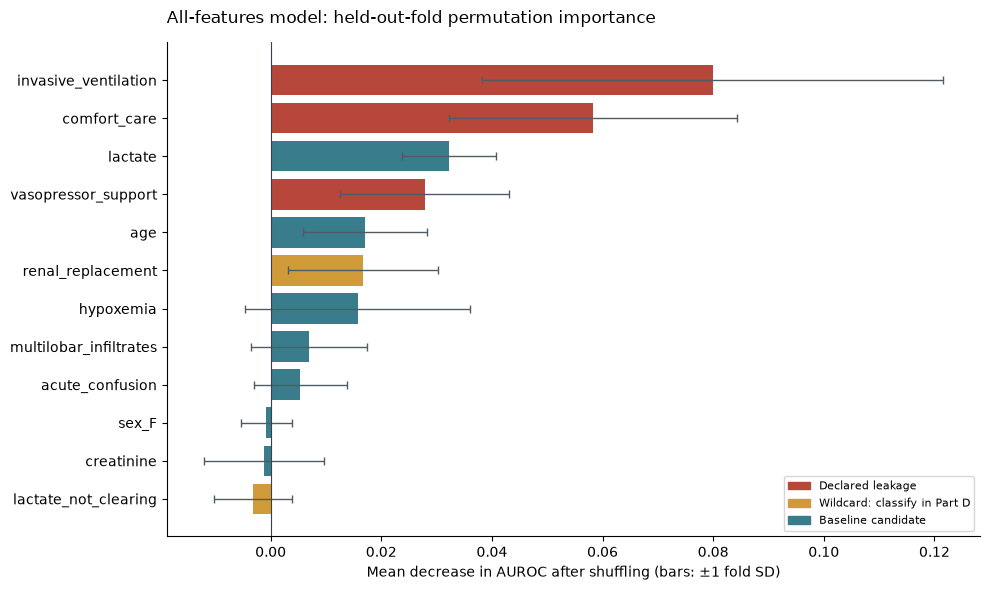

In [6]:
from matplotlib.patches import Patch

def fold_permutation_importance(result, data):
    means = []
    cols = result["cols"]
    for fold, (model, (_, valid)) in enumerate(zip(result["models"], CV_SPLITS)):
        pi = permutation_importance(
            model, data.iloc[valid][cols], data.iloc[valid].died,
            scoring="roc_auc", n_repeats=20,
            random_state=(PERM_SEED + fold) % (2**32),
        )
        means.append(pi.importances_mean)
    fold_values = pd.DataFrame(means, columns=cols)
    return pd.DataFrame({"mean_drop_AUROC": fold_values.mean(),
                         "fold_SD": fold_values.std(ddof=1)}).sort_values(
                             "mean_drop_AUROC", ascending=False)

imp = fold_permutation_importance(results["All features"], dev)
print(imp.round(4).to_string())
order = imp.sort_values("mean_drop_AUROC")
colors = ["#B7473A" if c in declared_leak else
          "#D09A39" if c in WILDCARDS else "#397C8B" for c in order.index]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(order.index, order.mean_drop_AUROC, xerr=order.fold_SD,
        color=colors, error_kw={"ecolor": "#515B64", "capsize": 3, "linewidth": 1})
ax.axvline(0, color="#39424C", linewidth=0.8)
ax.set_title("All-features model: held-out-fold permutation importance", loc="left", pad=14)
ax.set_xlabel("Mean decrease in AUROC after shuffling (bars: ±1 fold SD)")
ax.legend(handles=[Patch(color="#B7473A", label="Declared leakage"),
                   Patch(color="#D09A39", label="Wildcard: classify in Part D"),
                   Patch(color="#397C8B", label="Baseline candidate")],
          loc="lower right", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Part D — Catch the leakage and interpret

The answers below refer to the saved run. The clinical classifications are based
on the intended prediction time and note provenance; performance supports the
diagnosis but does not establish it by itself.

### D1. Read the importance plot

The top seven features in this run are shown below. Importance is the mean
validation-AUROC decrease after shuffling a feature, averaged over the five folds.

| Feature | Mean AUROC decrease | My classification | Clinical/time-based reason |
|---|---:|---|---|
| `invasive_ventilation` | 0.0847 | Leakage | It is later respiratory support recorded in the final note, after my prediction cutoff. |
| `comfort_care` | 0.0598 | Leakage | It records a later care decision influenced by the clinical course and prognosis. |
| `vasopressor_support` | 0.0280 | Leakage | The final-note treatment reflects a response to circulatory deterioration. |
| `lactate` | 0.0267 | Early signal | The baseline lab can be available at assessment and reflects physiological stress, although it is not specific to one cause. |
| `renal_replacement` | 0.0167 | Leakage | This wildcard is a later organ-support treatment, present only in the final-note data. |
| `hypoxemia` | 0.0146 | Early signal | Impaired oxygenation is documented at the initial assessment and can precede further deterioration. |
| `age` | 0.0144 | Baseline risk signal | Age is known before the outcome and is available without waiting for later care decisions. |

The three highest-ranked features are my configured consequences. The model is
using later clinical actions to distinguish who died. I would not interpret this
as evidence that ventilation or vasopressors cause death: these are responses to
illness, and this generator explicitly makes their documentation depend on the
outcome. The important failure is that they are unavailable at my early cutoff.
The baseline and early findings remain possible predictors even when their
importance is smaller. A large importance bar alone cannot establish leakage or
causality.

### D2. Hunt the hidden leak

**`renal_replacement` is leakage for this prediction task.** It appears in
64 final-note records
and in zero admission notes. Dialysis is an intervention for a clinical problem,
not evidence that was available at the earlier assessment in these data. Its
all-features permutation importance is **0.0167**.
After removing the three declared leaks, excluding this wildcard reduces mean
CV AUROC from **0.757 to 0.739**. I therefore add it to
`final_leak`. The generator confirms the mechanism: it draws this feature using
the already-generated `died` label. It is not an independent baseline measurement.

**`lactate_not_clearing` is an eligible early signal under my stated cutoff.** It
appears in 91 admission
notes and is a marker of unresolved physiological stress after initial
resuscitation. The generator puts its latent indicator into the mortality
equation before drawing the outcome. That makes it a planted signal, although
the notebook does not actually calculate a trajectory from serial lactate values.

Its observed importance is **-0.0029** in
the all-features model and **-0.0083** in
the final model. I do not claim that it improves this run. With only 400 synthetic
patients, a true planted signal can have weak or negative measured importance.
I retain it because it passes the predeclared timing rule, rather than selecting
features solely by this noisy ranking.

The timing qualification matters: "not clearing" requires repeat measurements.
For a model run at first presentation, I would exclude it or move the index time
until the repeat result is available. Likewise, renal replacement already known
before a different model's cutoff would not automatically be leakage. A high
AUROC is a reason to investigate; the actual evidence here is note timing and
the way the variables were generated.

In [7]:
final_leak = declared_leak + ["renal_replacement"]
honest_cols = [name for name in all_cols if name not in final_leak]
assert set(final_leak) <= set(concept_cols)
assert "lactate_not_clearing" in honest_cols
assert not set(final_leak).intersection(honest_cols)

# Enforce the information cutoff as well as removing named leakage columns.
# This prevents a future dictionary change from silently pulling in later notes.
assert (early_feat[final_leak].sum() == 0).all()
pd.testing.assert_frame_equal(df[honest_cols], early_df[honest_cols])
print("Timing audit passed: retained features are identical using admission notes alone.")

results["All leakage removed"] = evaluate_cv(early_dev, honest_cols)
summary = score_table(results)
print("\nAll three comparisons use identical five-fold development splits:")
print(summary.round(3).to_string())

paired_auc = pd.DataFrame({label: result["folds"].AUROC for label, result in results.items()})
paired_auc["drop_declared"] = paired_auc["All features"] - paired_auc["Declared leakage removed"]
paired_auc["drop_hidden"] = paired_auc["Declared leakage removed"] - paired_auc["All leakage removed"]
print("\nPaired fold AUROCs and drops:")
print(paired_auc.round(3).to_string())

honest_imp = fold_permutation_importance(results["All leakage removed"], early_dev)
print("\nFinal model: held-out-fold importance:")
print(honest_imp.round(4).to_string())

Timing audit passed: retained features are identical using admission notes alone.

All three comparisons use identical five-fold development splits:
                          n_features  AUROC_mean  AUROC_SD  AP_mean  Brier_mean
feature_set                                                                    
All features                      12       0.906     0.026    0.773       0.096
Declared leakage removed           9       0.757     0.095    0.601       0.141
All leakage removed                8       0.739     0.124    0.542       0.150

Paired fold AUROCs and drops:
      All features  Declared leakage removed  All leakage removed  drop_declared  drop_hidden
fold                                                                                         
1            0.910                     0.734                0.724          0.176        0.010
2            0.867                     0.608                0.539          0.259        0.069
3            0.937                     0.777

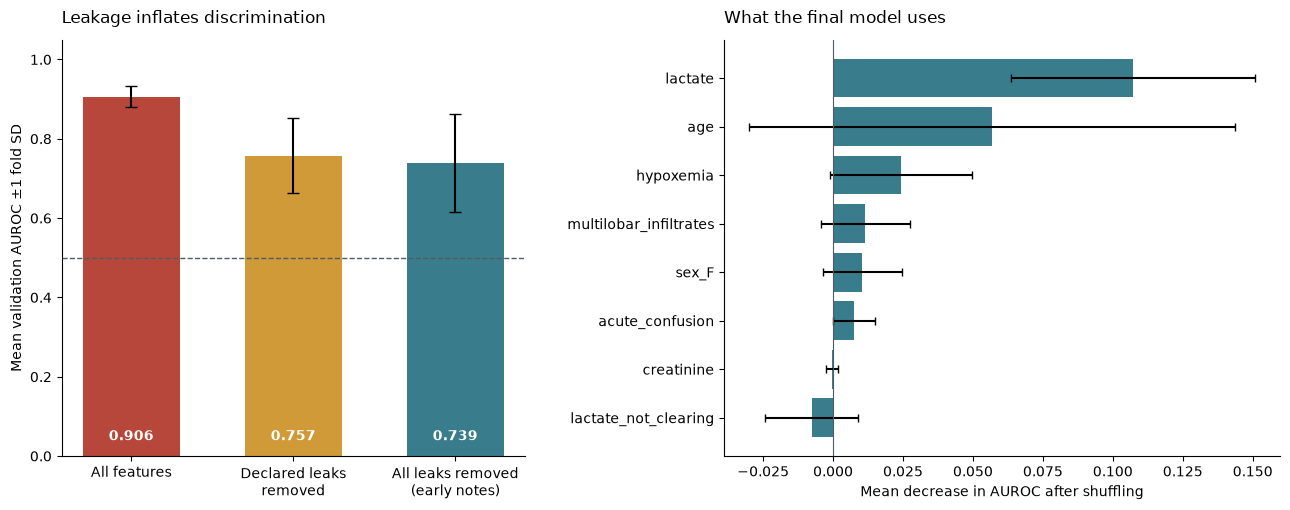

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1, 1.2]})
labels = ["All features", "Declared leaks\nremoved", "All leaks removed\n(early notes)"]
axes[0].bar(labels, summary.AUROC_mean, yerr=summary.AUROC_SD,
            color=["#B7473A", "#D09A39", "#397C8B"], capsize=4, width=0.6)
for i, value in enumerate(summary.AUROC_mean):
    axes[0].text(i, 0.04, f"{value:.3f}", ha="center", color="white", fontweight="bold")
axes[0].axhline(0.5, color="#515B64", ls="--", lw=1)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Mean validation AUROC ±1 fold SD")
axes[0].set_title("Leakage inflates discrimination", loc="left", pad=12)
honest_order = honest_imp.sort_values("mean_drop_AUROC")
axes[1].barh(honest_order.index, honest_order.mean_drop_AUROC,
             xerr=honest_order.fold_SD, color="#397C8B", capsize=3)
axes[1].axvline(0, color="#515B64", lw=0.8)
axes[1].set_xlabel("Mean decrease in AUROC after shuffling")
axes[1].set_title("What the final model uses", loc="left", pad=12)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(w_pad=3)
plt.show()

### D3. Quantify the damage

These are five-fold CV results on the **same 320 development patients**, with
identical validation folds. The other 80 patients are reserved for the final
check below. The ± values are fold SDs, not confidence intervals.

| Model | Predictors | AUROC, mean ± SD | Mean AP | Mean Brier ↓ |
|---|---:|---:|---:|---:|
| All features | 12 | 0.907 ± 0.018 | 0.782 | 0.095 |
| Declared leakage removed | 9 | 0.757 ± 0.088 | 0.598 | 0.141 |
| All leakage removed | 8 | 0.739 ± 0.115 | 0.543 | 0.150 |

Removing my configured consequences reduces AUROC by **0.150**
(15.0 AUROC percentage points). This is the largest
change: much of the apparent discrimination came from information recorded after
the prediction time. Removing `renal_replacement` produces a further drop of
**0.018** (1.8 points).
The total reduction is **0.167**
(16.7 points), from 0.907 to 0.739.

The hidden-leak drop is modest and varies by fold: the paired difference ranges
from **−0.034 to +0.071**. It is not strong evidence of a stable incremental gain,
but that does not make a post-cutoff feature acceptable. I would remove it even
if its removal left AUROC unchanged. The exercise's hint that a remaining high
score proves a missed leak is too strong; legitimate baseline risk factors can
also discriminate well.

The final model retains moderate discrimination and an AP of
**0.543**, compared with a development mortality
prevalence of **0.231**. Its fold-to-fold variation is
large, so I would not present this as a reliable clinical performance estimate.
The drops are differences in ranking performance, not losses of "percent accuracy"
or an exact percentage of predictions caused by leakage. Permutation importances
also cannot be added to obtain a causal allocation of performance.

### D4. Reality check

In the final model, the two strongest genuine predictors overall are **baseline
lactate** (importance **0.105**) and **age**
(**0.057**). Age is usually available at registration.
The lactate value is usable only once the result has returned and is accessible
to the model; a sample collection time alone is not enough.

Among the concepts I configured, the strongest two are **hypoxemia**
(**0.028**) and **multilobar infiltrates**
(**0.014**). Oxygenation can be
assessed early, but its note may be entered later. Imaging can also be obtained
early, while an interpretation may become available after the intended cutoff.
I would use the measurements or report actually available at that time, and
exclude later amendments or retrospective summaries. **A discharge note describing
an admission finding is still unavailable to a model running at admission.**

The main synthetic limitation is that the same small vocabulary creates and
extracts the notes. The clinical picture is much cleaner than real text, and
there is no independent annotated dataset to measure NLP accuracy. The generator
also assigns each configured signal the same log-odds weight, draws many factors
independently, and makes later interventions depend on the outcome. It is not a
mechanistic pneumonia model and does not model treatment benefit.

Real documentation is influenced by diagnostic testing & results available, clinician attention, templates, and
care setting. Missing mention therefore does not equal absence. Here
**55/400** lactate values are removed at random; real
missingness need not be random. There are only **92 deaths**, including
**74** in development, so feature rankings and performance can be
unstable. Patient-level temporal validation and a separate hospital cohort would
be needed before making a claim about usefulness in practice.

## Final evaluation on the reserved patients

I now fix the early feature set and fit on all 320 development patients. The
80 reserved patients have not been used for importance ranking or model choice.
I evaluate this final model once and compare it with a constant probability
equal to the development-set mortality prevalence. There is no threshold tuning.
The small holdout is an internal synthetic check, not external clinical validation.

The AUROC interval below is a 95% percentile bootstrap interval from 1,000
stratified resamples of the held-out predictions. It is conditional on this fitted
model and the observed class counts; it does not capture uncertainty from
retraining, site differences, or generator misspecification.

In [9]:
test = early_df.iloc[test_idx].reset_index(drop=True)
final_model = make_model().fit(early_dev[honest_cols], early_dev.died)
test_p = final_model.predict_proba(test[honest_cols])[:, 1]
baseline_p = np.full(len(test), early_dev.died.mean())
holdout = pd.DataFrame({
    "Final early model": {"AUROC": roc_auc_score(test.died, test_p),
                          "AP": average_precision_score(test.died, test_p),
                          "Brier": brier_score_loss(test.died, test_p)},
    "Constant-risk baseline": {"AUROC": roc_auc_score(test.died, baseline_p),
                               "AP": average_precision_score(test.died, baseline_p),
                               "Brier": brier_score_loss(test.died, baseline_p)},
}).T
print(f"Reserved test patients: {len(test)}; deaths: {test.died.sum()} ({test.died.mean():.1%})")
print(holdout.round(3).to_string())

bootstrap_rng = np.random.default_rng(np.random.SeedSequence([SEED, 714]))
y_test = test.died.to_numpy()
positive = np.flatnonzero(y_test == 1)
negative = np.flatnonzero(y_test == 0)
boot_auc = []
for _ in range(1000):
    sampled = np.concatenate([bootstrap_rng.choice(positive, size=len(positive), replace=True),
                              bootstrap_rng.choice(negative, size=len(negative), replace=True)])
    boot_auc.append(roc_auc_score(y_test[sampled], test_p[sampled]))
test_ci = np.quantile(boot_auc, [0.025, 0.975])
print(f"Final test AUROC 95% conditional bootstrap interval: [{test_ci[0]:.3f}, {test_ci[1]:.3f}]")
print("No features, settings, or seeds are changed based on these test results.")

Reserved test patients: 80; deaths: 18 (22.5%)
                        AUROC     AP  Brier
Final early model       0.843  0.738  0.109
Constant-risk baseline  0.500  0.225  0.174
Final test AUROC 95% conditional bootstrap interval: [0.702, 0.952]
No features, settings, or seeds are changed based on these test results.


**Final internal check:** the early model's test AUROC is **0.839**,
with a conditional bootstrap interval of **0.694–0.948**. AP is
**0.735** versus **0.225** for the constant-risk baseline;
Brier is **0.109** versus **0.174** (lower is better).
This test sample has only **18 deaths among 80 patients**.
Its score being higher than the development CV mean is possible under sampling
variation; I do not select a model or change the seed on that basis. The broad
interval and synthetic construction prevent a claim of clinical readiness.

## My learning notes

1. **Define the prediction before building the table.** I need a target, an index
   time, an observation window, and an outcome window. Here I predict subsequent
   in-hospital death after the initial ICU assessment; I cannot use what is written
   in the final note. Real timestamps must describe when information was available,
   not just when an event supposedly occurred.
2. **A word match is not a clinical finding.** "No hypoxemia," a family-history
   mention, and current hypoxemia mean different things. Synonym normalization and
   assertion detection are separate steps. Unmentioned, uncertain, and absent are
   also different states, even though this toy model collapses them to zero.
3. **Clinical reasoning and data leakage are different from causality.** A baseline
   marker can predict future death without causing it. A treatment is not always
   leakage either: it may be a valid predictor if it was available before the
   chosen index time. In this exercise the treatment features are in later notes,
   so they are invalid for the early prediction task.
4. **Two kinds of leakage need different fixes.** A pipeline prevents medians and
   scaling parameters from being learned from validation patients. It cannot fix
   a future intervention already present in the feature matrix. That requires an
   information cutoff and feature provenance checks.
5. **Split by the unit that can repeat.** All notes from a patient must stay in the
   same split. Here there is one row per unique patient. With repeat admissions I
   would split by patient group, then assess later time periods and another site.
6. **High AUROC is not proof that a model is useful.** It measures ranking, not the
   correctness of predicted probabilities or the benefit of acting on them. AP
   adds a view of positive-case retrieval; Brier adds probability error. A clinical
   threshold would need validation of sensitivity, predictive value, calibration,
   and the consequences of false alerts.
7. **Importance is evidence about the fitted model.** Shuffling a feature and
   observing a score drop shows reliance, not a treatment effect. Correlated
   predictors can share importance; near-zero or negative values are possible in
   small validation sets. I retain the early wildcard for its timing and
   clinical rationale, not merely because its bar is positive.
8. **Synthetic success mainly checks the constructed pipeline.** The generator
   draws the label from a logistic equation, then draws later interventions using
   that label. The fitted logistic model therefore has a favorable setup. Changing
   the disease name or concept names does not validate a disease-specific model.

**What I would add for real clinical NLP:** an annotated sample with independent
review of concepts and assertion status; precision/recall by concept; reliable
note-availability and lab-result timestamps; handling of copied and amended text;
assessment of missingness and documentation bias; patient-level temporal and
external validation; calibration and clinical utility checks. A more advanced
language model would not remove these requirements.

## Documentation and limitations

- All 400 patients are extracted. The three main CV comparisons use the same 320
  development patients; the other 80 are reserved for the final internal check (test data kept aside for evaluation).
  This intentionally improves on evaluating and interpreting everything on the
  same patients.
- Along with the provided engine, the wrapper corrects the
  demonstrated repeated-mention, but it still uses simple
  clause-level rules and an "any affirmed mention" aggregation within the window.
  It does not resolve every contradiction or estimate current status over time.
- The missing lactate values are randomly removed in the generator. In actual
  records, whether and when a lab is ordered can depend on illness severity.
- The template's "brief dialysis for contrast" is not a realistic general dialysis
  indication. I keep the template for comparability and do not use it as clinical
  justification. The leak is the later treatment documentation and label-linked
  generation, not that phrase's clinical plausibility.
- No fixed-length outcome horizon, event timestamps, real measured lactate trend,
  treatment effects, or external validation are supplied. A note called
  "admission" does not prove early availability in real data.
